# 15 · Interactive 2D maps and honest legends

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/content/15-interactive-2d-maps.ipynb)



Browser-only piplite prepares numpy, pandas, matplotlib and Plotly 6.5.0; native kernels use installed scientific packages. Local calculations use bundled helpers and inputs; Plotly rendering can require its versioned CDN and WebGL. Seeded monthly examples are synthetic. The C3S warming-level table gives model windows, Natural Earth provides real generalized coastlines, and the CDS catalogue is metadata. No authenticated CDS request, archive download or native regridding is run.

**Provenance:** `content/15-interactive-2d-maps.ipynb` at `b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a`; original SHA-256 `ffe97fd17134bde70b7a1d302d9f1b22abf22c0782c8b8aab88fd048955e7939`. Original course material MIT; C3S auxiliary table Apache-2.0, Natural Earth public domain and CDS catalogue metadata CC BY 4.0. Preserve source credits, licenses and artwork provenance.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original climate-globe illustration introducing Interactive 2D maps and honest legends; illustrative, not a data map](assets/atlas-splash.png)

# 15 · Interactive 2D maps and honest legends

**Guiding question:** What choices make a map easier to compare and harder to misread?

**Data:** Synthetic teaching examples  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-15  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** in-memory tables and figures; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=15-interactive-2d-maps.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

Use a sequential palette for ordered nonnegative quantities and a diverging
       palette with a meaningful centre for signed changes. Fix colour limits across
       comparisons; autoscaling can make different magnitudes look identical.

       This is a plate carrée map with longitude and latitude in degrees, not an
       equal-area projection. Zoom and hover are interactive. The bundled coastlines
       are public-domain Natural Earth data; the climate field is invented. No map
       service key, external tiles, or upload is required.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Explore an interactive field

In [2]:
lon, lat, field = regular_grid()
fig = map_figure(lon, lat, field, "Read the coordinates and colour scale · SYNTHETIC")
show(fig)
display(pd.DataFrame(field[::6, ::12], index=lat[::6], columns=lon[::12]).round(2))

Figure({
    'data': [{'colorbar': {'title': {'text': 'Δ °C'}},
              'colorscale': [[0.0, '#00224e'], [0.1111111111111111, '#123570'],
                             [0.2222222222222222, '#3b496c'], [0.3333333333333333,
                             '#575d6d'], [0.4444444444444444, '#707173'],
                             [0.5555555555555556, '#8a8678'], [0.6666666666666666,
                             '#a59c74'], [0.7777777777777778, '#c3b369'],
                             [0.8888888888888888, '#e1cc55'], [1.0, '#fee838']],
              'hovertemplate': 'lon %{x}°<br>lat %{y}°<br>Δ %{z:.2f} °C<extra></extra>',
              'type': 'heatmap',
              'x': {'bdata': ('AAAAAAAwZsAAAAAAAJBlwAAAAAAA8G' ... 'AAAADwZEAAAAAAAJBlQAAAAAAAMGZA'),
                    'dtype': 'f8'},
              'y': {'bdata': ('AAAAAADgVcAAAAAAAKBUwAAAAAAAYF' ... 'AAAABgU0AAAAAAAKBUQAAAAAAA4FVA'),
                    'dtype': 'f8'},
              'z': {'bdata': ('/uaDC3qiCEAplwyZv6IIQHovmyxKow' ... '+bLEqjCEAplwyZv6IIQP7mgwt6oghA'),
                    'dtype': 'f8',
                    'shape': '36, 72'}},
             {'hoverinfo': 'skip',
              'line': {'color': '#172d40', 'width': 0.7},
              'mode': 'lines',
              'showlegend': False,
              'type': 'scatter',
              'x': [-163.712896, -163.105801, -161.245113, ..., -106.94, -106.6,
                    None],
              'y': [-78.595667, -78.223339, -78.380177, ..., 73.46, 73.6, None]}],
    'layout': {'annotations': [{'showarrow': False,
                                'text': 'Made with Natural Earth · Plate carrée',
                                'x': 0,
                                'xref': 'paper',
                                'y': -0.18,
                                'yref': 'paper'}],
               'font': {'size': 14},
               'height': 470,
               'margin': {'b': 65, 'l': 65, 'r': 45, 't': 90},
               'template': '...',
               'title': {'text': 'Read the coordinates and colour scale · SYNTHETIC'},
               'xaxis': {'range': [-180, 180], 'title': {'text': 'Longitude (°)'}},
               'yaxis': {'range': [-90, 90], 'title': {'text': 'Latitude (°)'}}}
})

,-177.5,-117.5,-57.5,2.5,62.5,122.5
-87.5,3.08,3.09,3.11,3.11,3.10,3.09
-57.5,2.39,2.51,2.72,2.82,2.71,2.49
-27.5,1.41,1.60,1.95,2.12,1.93,1.57
2.5,1.00,1.22,1.62,1.80,1.59,1.19
32.5,1.55,1.74,2.07,2.23,2.05,1.71
62.5,2.55,2.65,2.84,2.92,2.82,2.64


## Compare fixed colour limits in a static fallback

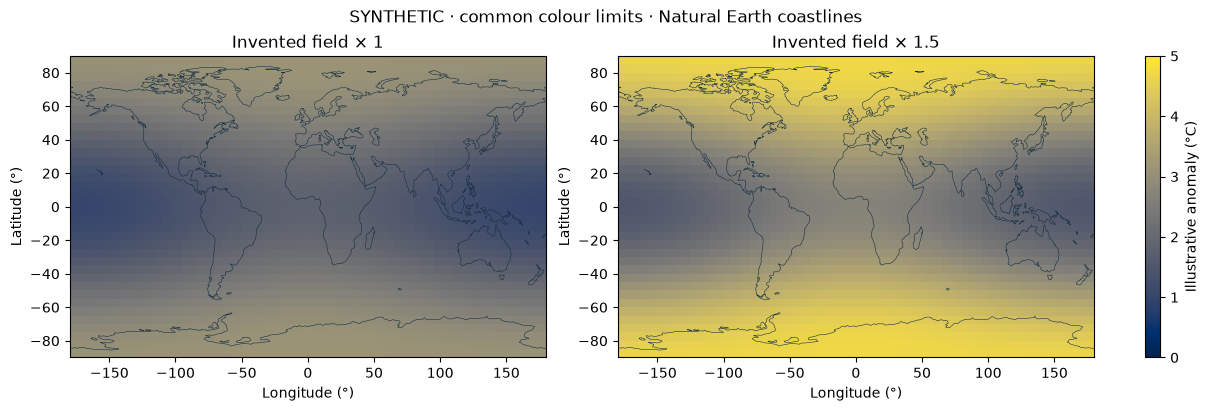

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, factor in zip(axes, [1, 1.5]):
    im = ax.pcolormesh(lon, lat, field*factor, cmap="cividis", vmin=0, vmax=5, shading="auto")
    for line in coastlines():
        for segment in np.split(line, np.where(np.abs(np.diff(line[:, 0])) > 180)[0]+1):
            ax.plot(segment[:, 0], segment[:, 1], color="#183044", lw=.4)
    ax.set(title=f"Invented field × {factor}", xlabel="Longitude (°)", ylabel="Latitude (°)", xlim=(-180, 180), ylim=(-90, 90))
fig.colorbar(im, ax=axes, label="Illustrative anomaly (°C)")
fig.suptitle("SYNTHETIC · common colour limits · Natural Earth coastlines")
plt.show()

## Try it and explain

Set independent colour limits in each panel. Which comparison becomes misleading?

**Interpretation check:** The same colour can represent different magnitudes. Retain common scales when the purpose is direct numerical comparison.

## Transfer to the official Atlas

Choose a fixed range in the official map legend and compare two periods. Describe the change numerically as well as visually.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [Natural Earth terms and contributors](https://www.naturalearthdata.com/about/terms-of-use/)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/content/credits.md) and [data guide](https://github.com/jltobias/JupyterLite-C3S-Atlas/blob/b41c3e1098a4fb94cef48b3044fe19c6ce7c1a1a/content/data-guide.md).

**Continue:** [Globes and three-dimensional climate maps](16-globes-and-3d-maps.ipynb)